<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/03_pytorch_computer_vision_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. PyTorch Computer Vision Exercises

The following is a collection of exercises based on computer vision fundamentals in PyTorch.

They're a bunch of fun.

You're going to get to write plenty of code!

## Resources

1. These exercises are based on [notebook 03 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/03_pytorch_computer_vision/).
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/_PibmqpEyhA).
  * **Note:** Going through these exercises took me just over 3 hours of solid coding, so you should expect around the same.
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [67]:
# Check for GPU
!nvidia-smi

Sun Oct 11 09:19:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P0             28W /   70W |     197MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [68]:
# Import torch
import torch

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

# TODO: Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device


2.11.0+cu130


'cuda'

## 1. What are 3 areas in industry where computer vision is currently being used?

## 2. Search "what is overfitting in machine learning" and write down a sentence about what you find.

## 3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each.
> **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.

## 4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

* Upload your own example image using the "upload" button on the website and see what happens in each layer of a CNN as your image passes through it.

## 5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.

In [69]:
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

train_data = MNIST(root= "data", train =True, download = True, transform=ToTensor())
test_data = MNIST(root= "data", train =False, download = True, transform=ToTensor())

In [70]:
len(train_data), len(test_data)

(60000, 10000)

## 6. Visualize at least 5 different samples of the MNIST training dataset.

/tmp/ipykernel_512/3434389769.py:7: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  img = np.array(img)


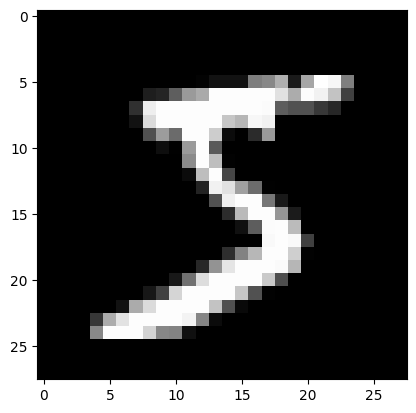

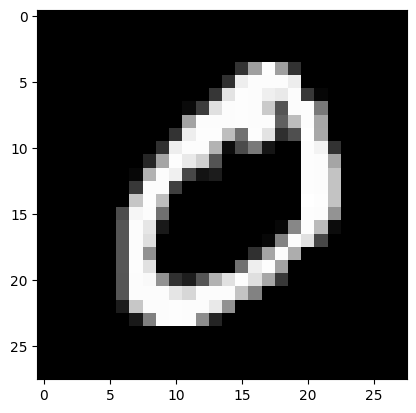

In [71]:
import matplotlib.pyplot as plt
import numpy as np

for i in range(2):
  img , label = train_data[i]
  img = img.squeeze()
  img = np.array(img)
  plt.imshow(img, cmap = "gray")
  plt.show()

## 7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.

In [72]:
from torch.utils.data import DataLoader

batch_size = 64
train_dataloader = DataLoader(train_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

## 8. Recreate `model_2` used in notebook 03 (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.

In [73]:
from torch.nn.modules import ReLU
import torch.nn as nn
class CNN_model(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor  = nn.Sequential(
        nn.Conv2d(in_channels = 1 , out_channels = 10, kernel_size= 5, padding = 0, stride = 1),
        nn.BatchNorm2d(10),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride =2),
        nn.Conv2d(in_channels = 10 , out_channels = 5, kernel_size= 3, padding = 0, stride = 1),
        nn.BatchNorm2d(5),
        nn.ReLU(),
        nn.Dropout2d(0.2),
        nn.MaxPool2d(kernel_size = 2, stride =2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features = 125, out_features = 64),
        nn.ReLU(),
        nn.Dropout2d(0.3),
        nn.Linear(in_features = 64, out_features = 10)
    )

  def forward(self , x):
    x = self.feature_extractor(x)
    x = self.classifier(x)
    return x

torch.manual_seed(42)
torch.cuda.manual_seed(42)
model = CNN_model().to(device)
model


CNN_model(
  (feature_extractor): Sequential(
    (0): Conv2d(1, 10, kernel_size=(5, 5), stride=(1, 1))
    (1): BatchNorm2d(10, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(10, 5, kernel_size=(3, 3), stride=(1, 1))
    (5): BatchNorm2d(5, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout2d(p=0.2, inplace=False)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=125, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout2d(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [74]:
#print no of model parameters

sum(p.numel() for p in model.parameters())

9459

## 9. Train the model you built in exercise 8. for 5 epochs on CPU and GPU and see how long it takes on each.

In [75]:
epochs = 30

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params = model.parameters() , lr = 0.001 , weight_decay= 0.02)


for epoch in range(epochs):
  train_loss = 0
  model.train()
  for batch , (x,y) in enumerate(train_dataloader):
    x , y = x.to(device) , y.to(device)
    model.to(device)
    y_pred = model(x)
    loss = loss_fn(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_loss+= loss.item()

  train_loss = train_loss/len(train_dataloader)
  print("Train loss is ", train_loss)


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 2-D input to dropout2d, which is deprecated and will result in an error in a future release. To retain the behavior and silence this warning, please use dropout instead. Note that dropout2d exists to provide channel-wise dropout on inputs with 2 spatial dimensions, a channel dimension, and an optional batch dimension (i.e. 3D or 4D inputs).
  return F.dropout2d(input, self.p, self.training, self.inplace)


Train loss is  0.4804605819793271
Train loss is  0.2529903430380483
Train loss is  0.23488318391922694
Train loss is  0.22171216002151148
Train loss is  0.2165119577564601
Train loss is  0.2127452056005057
Train loss is  0.2105965135472098
Train loss is  0.21063858099869573
Train loss is  0.20806059599923554
Train loss is  0.20660763722794778
Train loss is  0.20672216904021976
Train loss is  0.20663683481419137
Train loss is  0.20320542908108818
Train loss is  0.20401274964515206
Train loss is  0.20221409122588666
Train loss is  0.2026385712201026
Train loss is  0.19914047300879126
Train loss is  0.20059923398326326
Train loss is  0.20122760479082305
Train loss is  0.1986176857689042
Train loss is  0.1987718653712255
Train loss is  0.20176807227633844
Train loss is  0.1975329708713077
Train loss is  0.19585902442428857
Train loss is  0.19800586251418856
Train loss is  0.19672392109937187
Train loss is  0.1978558007993106
Train loss is  0.199931997194219
Train loss is  0.197490664008361

## 10. Make predictions using your trained model and visualize at least 5 of them comparing the prediciton to the target label.

In [76]:
model.eval()
correct = 0
with torch.inference_mode():
  for x, y in test_dataloader:
    x ,y = x.to(device) , y.to(device)
    y_pred = model(x)
    y_pred = y_pred.argmax(dim =1)
    # print(y_pred, y)
    correct += (y_pred == y).sum()
    # print(correct)


accuracy = correct / (len(test_dataloader) * batch_size)
print(f"Accuracy is {accuracy}")


Accuracy is 0.9655653238296509


## 11. Plot a confusion matrix comparing your model's predictions to the truth labels.

<Axes: >

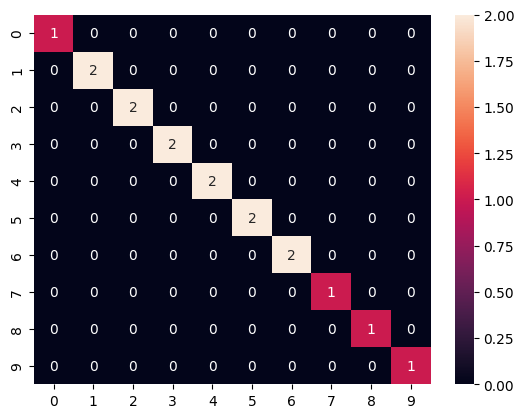

In [77]:
#plot confusion matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

confusion_matrix = confusion_matrix(y_pred.cpu(), y.cpu())  # only for last batch.
sns.heatmap(confusion_matrix, annot=True, fmt='d')

## 12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?

## 13. Use a model similar to the trained `model_2` from notebook 03 to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset.
* Then plot some predictions where the model was wrong alongside what the label of the image should've been.
* After visualing these predictions do you think it's more of a modelling error or a data error?
* As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?